# LLaMA style upgrade: RoPE, RMSNorm, SwiGLU, grouped query attention, KV cache

The previous notebook built a GPT-2 style model. This notebook upgrades the architecture to the design used by LLaMA, Mistral and most recent open models, and measures what each change does.

Changes, one by one:

- RoPE (rotary position embeddings) replace the learned position table. Positions are encoded by rotating queries and keys, so attention scores depend only on the distance between two tokens.
- RMSNorm replaces LayerNorm. It only rescales by the root mean square and has no mean subtraction.
- SwiGLU replaces the GELU feed forward block. It uses a gated feed forward with three matrices.
- Grouped query attention (GQA) shares each key and value head between several query heads, which shrinks the KV cache.
- A KV cache makes generation fast by storing keys and values of earlier tokens instead of recomputing them.

One model class implements both families through config flags, so the ablation changes exactly one thing at a time. All autograd is PyTorch's own; only the model, not the gradient computation, is written from scratch.

The notebook starts with correctness tests for every new piece, then runs the ablation on Shakespeare.

In [1]:
import os, math, time, random, urllib.request
from dataclasses import dataclass, replace

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0); torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

os.makedirs("data", exist_ok=True)
if not os.path.exists("data/input.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "data/input.txt")
text = open("data/input.txt", encoding="utf-8").read()

class Data:
    def __init__(self, text):
        chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(chars)}
        self.itos = {i: c for c, i in self.stoi.items()}
        self.vocab_size = len(chars)
        ids = torch.tensor([self.stoi[c] for c in text], dtype=torch.long)
        n = int(0.9 * len(ids))
        self.train, self.val = ids[:n], ids[n:]

    def encode(self, s):
        return [self.stoi[c] for c in s]

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)

    def get_batch(self, split, batch_size, block_size, generator=None, device=None):
        d = self.train if split == "train" else self.val
        ix = torch.randint(len(d) - block_size - 1, (batch_size,), generator=generator)
        x = torch.stack([d[i:i + block_size] for i in ix])
        y = torch.stack([d[i + 1:i + 1 + block_size] for i in ix])
        return (x.to(device), y.to(device)) if device else (x, y)

data = Data(text)
print("vocab size:", data.vocab_size, "| train tokens:", len(data.train))

device: cpu | torch 2.15.0+cu132
vocab size: 65 | train tokens: 1003854


## The building blocks

RMSNorm: divide each vector by its root mean square, then multiply by a learned scale. LayerNorm is kept for the GPT-2 style variant, without a bias to match.

In [2]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        xf = x.float()
        out = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return out.type_as(x) * self.weight

class LayerNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        xf = x.float()
        out = (xf - xf.mean(-1, keepdim=True)) / torch.sqrt(xf.var(-1, keepdim=True, unbiased=False) + self.eps)
        return out.type_as(x) * self.weight

RoPE. The head vector is split into pairs of dimensions. Pair i is rotated by the angle position times theta_i, where theta_i = base^(-2i/d). Rotating the query at position m and the key at position n means their dot product depends on the rotation by (m - n) only. The angles are computed on the fly from absolute positions, so a KV cache can continue from any position.

In [3]:
def rope_cos_sin(positions, head_dim, theta=10000.0):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2, device=positions.device).float() / head_dim))
    angles = positions.float()[:, None] * inv_freq[None, :]          # (T, head_dim / 2)
    emb = torch.cat([angles, angles], dim=-1)                          # same angle for both members of a pair
    return emb.cos(), emb.sin()

def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)

def apply_rope(x, cos, sin):
    xf = x.float()
    return (xf * cos + rotate_half(xf) * sin).type_as(x)

The model. The config flags select the components: pos is "rope" or "learned", norm is "rms" or "layer", mlp is "swiglu" or "gelu", and n_kv_head sets how many key and value heads there are (equal to n_head means ordinary multi head attention, 1 means multi query attention).

The attention layer accepts an optional cache. New keys and values are appended to the cached ones, and the mask is built so that each new query can see exactly the keys at or before its own position.

In [4]:
@dataclass
class Config:
    block_size: int = 128
    vocab_size: int = 65
    n_layer: int = 4
    n_head: int = 4
    n_kv_head: int = 2
    n_embd: int = 128
    pos: str = "rope"          # "rope" or "learned"
    norm: str = "rms"          # "rms" or "layer"
    mlp: str = "swiglu"        # "swiglu" or "gelu"
    dropout: float = 0.0
    rope_theta: float = 10000.0

def make_norm(cfg):
    return RMSNorm(cfg.n_embd) if cfg.norm == "rms" else LayerNorm(cfg.n_embd)

def swiglu_hidden(n_embd, multiple_of=32):
    return multiple_of * ((int(8 * n_embd / 3) + multiple_of - 1) // multiple_of)     # about 8/3 of the width

class Attention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0 and cfg.n_head % cfg.n_kv_head == 0
        self.cfg = cfg
        self.hd = cfg.n_embd // cfg.n_head
        self.n_rep = cfg.n_head // cfg.n_kv_head
        self.wq = nn.Linear(cfg.n_embd, cfg.n_head * self.hd, bias=False)
        self.wk = nn.Linear(cfg.n_embd, cfg.n_kv_head * self.hd, bias=False)
        self.wv = nn.Linear(cfg.n_embd, cfg.n_kv_head * self.hd, bias=False)
        self.wo = nn.Linear(cfg.n_head * self.hd, cfg.n_embd, bias=False)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, start_pos=0, cache=None, use_cache=False):
        B, T, _ = x.shape
        cfg = self.cfg
        q = self.wq(x).view(B, T, cfg.n_head, self.hd).transpose(1, 2)
        k = self.wk(x).view(B, T, cfg.n_kv_head, self.hd).transpose(1, 2)
        v = self.wv(x).view(B, T, cfg.n_kv_head, self.hd).transpose(1, 2)
        if cfg.pos == "rope":
            cos, sin = rope_cos_sin(torch.arange(start_pos, start_pos + T, device=x.device), self.hd, cfg.rope_theta)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if cache is not None:
            k = torch.cat([cache[0], k], dim=2)
            v = torch.cat([cache[1], v], dim=2)
        new_cache = (k, v) if use_cache else None
        S = k.size(2)
        if self.n_rep > 1:                                   # each key/value head serves n_rep query heads
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
        p = cfg.dropout if self.training else 0.0
        if T == S:
            y = F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
        elif T == 1:
            y = F.scaled_dot_product_attention(q, k, v, dropout_p=p)             # one new token sees everything cached
        else:
            mask = torch.ones(T, S, dtype=torch.bool, device=x.device).tril(diagonal=S - T)
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)
        y = y.transpose(1, 2).contiguous().view(B, T, cfg.n_head * self.hd)
        return self.drop(self.wo(y)), new_cache

class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        h = swiglu_hidden(cfg.n_embd)
        self.w1 = nn.Linear(cfg.n_embd, h, bias=False)       # gate
        self.w3 = nn.Linear(cfg.n_embd, h, bias=False)       # value
        self.w2 = nn.Linear(h, cfg.n_embd, bias=False)       # back down
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.w2(F.silu(self.w1(x)) * self.w3(x)))

class GeluMLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.w1 = nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=False)
        self.w2 = nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=False)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.w2(F.gelu(self.w1(x))))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n1, self.attn = make_norm(cfg), Attention(cfg)
        self.n2, self.mlp = make_norm(cfg), (SwiGLU(cfg) if cfg.mlp == "swiglu" else GeluMLP(cfg))

    def forward(self, x, start_pos=0, cache=None, use_cache=False):
        a, new_cache = self.attn(self.n1(x), start_pos, cache, use_cache)
        x = x + a
        return x + self.mlp(self.n2(x)), new_cache

def sample_next(logits, temperature=1.0, top_k=None):
    logits = logits / max(temperature, 1e-8)
    if top_k is not None:
        kth = torch.topk(logits, min(top_k, logits.size(-1)))[0][:, [-1]]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    return torch.multinomial(F.softmax(logits, dim=-1), 1)

class Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.wpe = nn.Embedding(cfg.block_size, cfg.n_embd) if cfg.pos == "learned" else None
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm = make_norm(cfg)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)
        for n, p in self.named_parameters():
            if n.endswith("wo.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    def forward(self, idx, targets=None, kv_caches=None, start_pos=0, use_cache=False):
        B, T = idx.shape
        x = self.wte(idx)
        if self.wpe is not None:
            assert start_pos + T <= self.cfg.block_size, "learned positions cannot go past block_size"
            x = x + self.wpe(torch.arange(start_pos, start_pos + T, device=idx.device))
        x = self.drop(x)
        new_caches = []
        for i, blk in enumerate(self.blocks):
            x, c = blk(x, start_pos, None if kv_caches is None else kv_caches[i], use_cache)
            new_caches.append(c)
        logits = self.lm_head(self.norm(x))
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1)) if targets is not None else None
        return logits, loss, (new_caches if use_cache else None)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, use_cache=True):
        was_training = self.training
        self.eval()
        bs = self.cfg.block_size
        if not use_cache:
            for _ in range(max_new_tokens):
                logits, _, _ = self(idx[:, -bs:])
                idx = torch.cat([idx, sample_next(logits[:, -1], temperature, top_k)], dim=1)
        else:
            if self.wpe is not None:
                assert idx.size(1) + max_new_tokens <= bs, "with learned positions the whole sequence must fit in block_size"
            ctx = idx[:, -bs:]
            logits, _, caches = self(ctx, use_cache=True)
            pos = ctx.size(1)
            for _ in range(max_new_tokens):
                nxt = sample_next(logits[:, -1], temperature, top_k)
                idx = torch.cat([idx, nxt], dim=1)
                if caches[0][0].size(2) >= bs:                 # sliding window: keep the newest keys only
                    caches = [(k[:, :, -(bs - 1):], v[:, :, -(bs - 1):]) for k, v in caches]
                logits, _, caches = self(nxt, kv_caches=caches, start_pos=pos, use_cache=True)
                pos += 1
        self.train(was_training)
        return idx

## Correctness tests

Each new component is checked against a plain reference or a mathematical property.

In [5]:
torch.manual_seed(0)

# 1. RMSNorm matches the formula (and PyTorch's own implementation when it exists)
x = torch.randn(4, 9, 64) * 5 + 3
n = RMSNorm(64)
with torch.no_grad():
    n.weight.copy_(torch.randn(64))
ref = x / torch.sqrt((x ** 2).mean(-1, keepdim=True) + 1e-5) * n.weight
assert torch.allclose(n(x), ref, atol=1e-5)
if hasattr(F, "rms_norm"):
    assert torch.allclose(n(x), F.rms_norm(x, (64,), n.weight, 1e-5), atol=1e-5)
print("1. RMSNorm matches the formula")

# 2. RoPE: matches an explicit rotation, preserves length, is the identity at position 0, and attention scores depend only on distance
d = 8
v = torch.randn(1, 1, 3, d)
pos = torch.tensor([0, 3, 7])
cos, sin = rope_cos_sin(pos, d)
out = apply_rope(v, cos, sin)
for ti, p in enumerate([0, 3, 7]):
    for i in range(d // 2):
        ang = p * 10000.0 ** (-2 * i / d)
        a, b = v[0, 0, ti, i].item(), v[0, 0, ti, i + d // 2].item()
        assert abs(out[0, 0, ti, i].item() - (a * math.cos(ang) - b * math.sin(ang))) < 1e-5
        assert abs(out[0, 0, ti, i + d // 2].item() - (a * math.sin(ang) + b * math.cos(ang))) < 1e-5
assert torch.allclose(out[0, 0, 0], v[0, 0, 0], atol=1e-6)
assert torch.allclose(out.norm(dim=-1), v.norm(dim=-1), atol=1e-5)
q0, k0 = torch.randn(d), torch.randn(d)
def score(m, n_):
    cm, sm = rope_cos_sin(torch.tensor([m]), d); cn, sn = rope_cos_sin(torch.tensor([n_]), d)
    return (apply_rope(q0[None, None, None], cm, sm) * apply_rope(k0[None, None, None], cn, sn)).sum().item()
base = score(10, 4)
for shift in (1, 25, 300):
    assert abs(score(10 + shift, 4 + shift) - base) < 1e-3, shift
assert abs(score(10, 4) - score(11, 4)) > 1e-4          # but changing the distance does change the score
print("2. RoPE is a rotation, is the identity at position 0, and scores depend only on relative distance")

# 3. SwiGLU equals its formula, and its size is close to the 4x GELU block
cfg = Config(n_embd=96)
mlp = SwiGLU(cfg)
x = torch.randn(3, 5, 96)
assert torch.allclose(mlp(x), mlp.w2(F.silu(x @ mlp.w1.weight.T) * (x @ mlp.w3.weight.T)), atol=1e-6)
p_swi = sum(p.numel() for p in SwiGLU(cfg).parameters()); p_gelu = sum(p.numel() for p in GeluMLP(cfg).parameters())
assert abs(p_swi - p_gelu) / p_gelu < 0.05
print(f"3. SwiGLU matches its formula; parameters {p_swi} vs GELU block {p_gelu}")

# 4. grouped query attention equals an explicit loop over heads (head h uses key/value head h // group size)
def reference_attention(attn, x):
    B, T, _ = x.shape
    cfg = attn.cfg
    q = attn.wq(x).view(B, T, cfg.n_head, attn.hd)
    k = attn.wk(x).view(B, T, cfg.n_kv_head, attn.hd)
    v = attn.wv(x).view(B, T, cfg.n_kv_head, attn.hd)
    out = torch.zeros(B, T, cfg.n_head, attn.hd)
    for h in range(cfg.n_head):
        g = h // attn.n_rep
        scores = torch.einsum("btd,bsd->bts", q[:, :, h], k[:, :, g]) / math.sqrt(attn.hd)
        scores = scores.masked_fill(torch.triu(torch.ones(T, T), 1).bool(), float("-inf"))
        out[:, :, h] = torch.einsum("bts,bsd->btd", F.softmax(scores, -1), v[:, :, g])
    return attn.wo(out.reshape(B, T, cfg.n_head * attn.hd))
for n_kv in (4, 2, 1):                                   # full multi head, grouped, multi query
    attn = Attention(Config(n_head=4, n_kv_head=n_kv, n_embd=64, pos="learned")).eval()
    x = torch.randn(2, 10, 64)
    assert torch.allclose(attn(x)[0], reference_attention(attn, x), atol=1e-5), n_kv
print("4. attention with 4, 2 and 1 key/value heads matches an explicit per head reference")

# 5. causality of the full model: for every pos / norm / mlp setting, later tokens never change earlier logits
for pos in ("rope", "learned"):
    for norm in ("rms", "layer"):
        for mlp_kind in ("swiglu", "gelu"):
            m = Model(Config(block_size=32, n_layer=2, n_embd=64, pos=pos, norm=norm, mlp=mlp_kind)).eval()
            x = torch.randint(0, 65, (2, 32)); base_logits = m(x)[0]
            for t in (1, 9, 20):
                x2 = x.clone(); x2[:, t:] = torch.randint(0, 65, x2[:, t:].shape)
                assert torch.allclose(base_logits[:, :t], m(x2)[0][:, :t], atol=1e-6), (pos, norm, mlp_kind, t)
print("5. no information from future tokens leaks, for all 8 combinations of position encoding, norm and MLP")

# 6. parameter count formula for the LLaMA style model
cfg = Config(block_size=64, n_layer=3, n_head=4, n_kv_head=2, n_embd=64)
m = Model(cfg)
hd = cfg.n_embd // cfg.n_head
per_layer = cfg.n_embd * cfg.n_head * hd + 2 * cfg.n_embd * cfg.n_kv_head * hd + cfg.n_head * hd * cfg.n_embd + 3 * cfg.n_embd * swiglu_hidden(cfg.n_embd) + 2 * cfg.n_embd
expected = cfg.vocab_size * cfg.n_embd + cfg.n_layer * per_layer + cfg.n_embd
assert m.num_params() == expected, (m.num_params(), expected)
print(f"6. parameter count {m.num_params()} matches the formula")

1. RMSNorm matches the formula
2. RoPE is a rotation, is the identity at position 0, and scores depend only on relative distance
3. SwiGLU matches its formula; parameters 73728 vs GELU block 73728
4. attention with 4, 2 and 1 key/value heads matches an explicit per head reference
5. no information from future tokens leaks, for all 8 combinations of position encoding, norm and MLP
6. parameter count 152064 matches the formula


KV cache tests. Decoding one token at a time with a cache must give exactly the logits of a full forward pass, for every position, including when a chunk of the prompt is processed at once first. Cached and uncached generation must produce identical tokens.

In [6]:
for kwargs in (dict(pos="rope", n_kv_head=2), dict(pos="rope", n_kv_head=1), dict(pos="learned", norm="layer", mlp="gelu", n_kv_head=4)):
    torch.manual_seed(1)
    m = Model(Config(block_size=48, n_layer=3, n_embd=64, **kwargs)).eval()
    x = torch.randint(0, 65, (2, 48))
    with torch.no_grad():
        full, _, _ = m(x)
        caches, outs = None, []
        for t in range(48):                                               # token by token
            lg, _, caches = m(x[:, t:t + 1], kv_caches=caches, start_pos=t, use_cache=True)
            outs.append(lg)
        assert torch.allclose(full, torch.cat(outs, 1), atol=1e-4), kwargs
        lg0, _, caches = m(x[:, :20], use_cache=True)                    # a chunk first, then single tokens
        outs = [lg0]
        for t in range(20, 48):
            lg, _, caches = m(x[:, t:t + 1], kv_caches=caches, start_pos=t, use_cache=True)
            outs.append(lg)
        assert torch.allclose(full, torch.cat(outs, 1), atol=1e-4), kwargs
        lg1, _, caches = m(x[:, :10], use_cache=True)                    # a chunk that is not a single token, on top of a cache
        lg2, _, _ = m(x[:, 10:30], kv_caches=caches, start_pos=10, use_cache=True)
        assert torch.allclose(full[:, 10:30], lg2, atol=1e-4), kwargs
    torch.manual_seed(2); a = m.generate(x[:, :5], 40, top_k=1, use_cache=True)
    torch.manual_seed(2); b = m.generate(x[:, :5], 40, top_k=1, use_cache=False)
    assert torch.equal(a, b), kwargs
    torch.manual_seed(7); a = m.generate(x[:, :3], 30, temperature=0.9, top_k=10, use_cache=True)
    torch.manual_seed(7); b = m.generate(x[:, :3], 30, temperature=0.9, top_k=10, use_cache=False)
    assert torch.equal(a, b), kwargs
print("7. KV cache gives the same logits as a full forward pass (token by token, chunked, and chunk on cache) and the same generated tokens")

# generation past the context window with the sliding window cache runs and stays in range (rope only)
m = Model(Config(block_size=32, n_layer=2, n_embd=64)).eval()
out = m.generate(torch.zeros(1, 1, dtype=torch.long), 100)
assert out.shape == (1, 101) and out.max() < 65
print("   sliding window generation past block_size works for the RoPE model")

# 8. each family can memorize one batch
for kwargs in (dict(), dict(pos="learned", norm="layer", mlp="gelu", n_kv_head=4)):
    torch.manual_seed(3)
    m = Model(Config(block_size=16, n_layer=2, n_embd=64, **kwargs))
    xb = torch.randint(0, 65, (4, 16)); yb = torch.randint(0, 65, (4, 16))
    opt = torch.optim.AdamW(m.parameters(), 3e-3, weight_decay=0.0)
    for _ in range(300):
        _, loss, _ = m(xb, yb); opt.zero_grad(); loss.backward(); opt.step()
    assert loss.item() < 0.05, (kwargs, loss.item())
    assert all(p.grad is not None and torch.isfinite(p.grad).all() and p.grad.abs().sum() > 0 for p in m.parameters())
print("8. both model families memorize a batch and every parameter gets a gradient")

7. KV cache gives the same logits as a full forward pass (token by token, chunked, and chunk on cache) and the same generated tokens
   sliding window generation past block_size works for the RoPE model


8. both model families memorize a batch and every parameter gets a gradient


## KV cache speed and memory

Without a cache, every new token requires a forward pass over the whole context so far. With a cache, it requires one token. The cache itself stores two tensors per layer, and grouped query attention makes it smaller in proportion to the number of key and value heads.

In [7]:
torch.manual_seed(0)
bench = Model(Config(block_size=512, n_layer=4, n_head=4, n_kv_head=2, n_embd=128)).eval()
start = torch.zeros(1, 1, dtype=torch.long)
res = {}
for use_cache in (False, True):
    t0 = time.time()
    torch.manual_seed(0)
    res[use_cache] = bench.generate(start, 400, top_k=1, use_cache=use_cache)
    dt = time.time() - t0
    print(f"use_cache={use_cache}: {400 / dt:7.1f} tokens/s ({dt:.1f}s for 400 tokens)")
    if use_cache:
        speedup = t_nocache / dt
    else:
        t_nocache = dt
assert torch.equal(res[False], res[True])
print(f"identical output, cache is {speedup:.1f}x faster")
assert speedup > 2

print("\ncache size for one sequence of 512 tokens (float32, 4 layers, 128 wide, 4 query heads)")
for n_kv, name in ((4, "multi head (4 kv heads)"), (2, "grouped query (2 kv heads)"), (1, "multi query (1 kv head)")):
    b = 2 * 4 * n_kv * 512 * (128 // 4) * 4
    print(f"  {name:28s}: {b / 1024:7.0f} KiB")

use_cache=False:   235.8 tokens/s (1.7s for 400 tokens)


use_cache=True:   891.3 tokens/s (0.4s for 400 tokens)
identical output, cache is 3.8x faster

cache size for one sequence of 512 tokens (float32, 4 layers, 128 wide, 4 query heads)
  multi head (4 kv heads)     :    2048 KiB
  grouped query (2 kv heads)  :    1024 KiB
  multi query (1 kv head)     :     512 KiB


## Ablation on Shakespeare

Five variants, each adding one change on top of the previous one:

1. GPT-2 style: learned positions, LayerNorm, GELU, 4 key/value heads.
2. plus RoPE
3. plus RMSNorm
4. plus SwiGLU
5. plus grouped query attention (2 key/value heads). This is the full LLaMA style model.

Everything else is identical: the same width, depth, data batches, evaluation batches, optimizer settings and step count. Each variant is trained with two seeds. The data are 1 MB of text and the runs are short, so differences of a few hundredths in loss are within noise. What the experiment measures is how quickly each design learns under a fixed small budget.

In [8]:
@dataclass
class TrainConfig:
    batch_size: int = 32
    max_iters: int = 700
    lr: float = 2e-3
    min_lr: float = 2e-4
    warmup_iters: int = 50
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_interval: int = 100
    eval_iters: int = 40

def get_lr(it, tc):
    if it < tc.warmup_iters:
        return tc.lr * (it + 1) / (tc.warmup_iters + 1)
    if it > tc.max_iters:
        return tc.min_lr
    ratio = (it - tc.warmup_iters) / (tc.max_iters - tc.warmup_iters)
    return tc.min_lr + 0.5 * (1 + math.cos(math.pi * ratio)) * (tc.lr - tc.min_lr)

@torch.no_grad()
def evaluate(model, tc, device):
    model.eval()
    g = torch.Generator().manual_seed(123)                 # the same validation batches for every variant
    total = 0.0
    for _ in range(tc.eval_iters):
        x, y = data.get_batch("val", tc.batch_size, model.cfg.block_size, g, device)
        total += model(x, y)[1].item()
    model.train()
    return total / tc.eval_iters

def fit(model, tc, seed, device):
    model.to(device).train()
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": tc.weight_decay}, {"params": no_decay, "weight_decay": 0.0}], lr=tc.lr, betas=(0.9, 0.99))
    g = torch.Generator().manual_seed(seed)                # the same training batches for every variant
    curve = []
    t0 = time.time()
    for it in range(tc.max_iters + 1):
        if it % tc.eval_interval == 0 or it == tc.max_iters:
            curve.append((it, evaluate(model, tc, device)))
        if it == tc.max_iters:
            break
        for gr in opt.param_groups:
            gr["lr"] = get_lr(it, tc)
        x, y = data.get_batch("train", tc.batch_size, model.cfg.block_size, g, device)
        _, loss, _ = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), tc.grad_clip)
        opt.step()
    return curve, time.time() - t0

base_cfg = Config(block_size=128, vocab_size=data.vocab_size, n_layer=4, n_head=4, n_kv_head=4, n_embd=128, pos="learned", norm="layer", mlp="gelu")
variants = {
    "GPT-2 style": base_cfg,
    "+ RoPE": replace(base_cfg, pos="rope"),
    "+ RMSNorm": replace(base_cfg, pos="rope", norm="rms"),
    "+ SwiGLU": replace(base_cfg, pos="rope", norm="rms", mlp="swiglu"),
    "+ GQA (LLaMA style)": replace(base_cfg, pos="rope", norm="rms", mlp="swiglu", n_kv_head=2),
}
tc = TrainConfig()
seeds = (0, 1)
results, last_models = {}, {}
for name, cfg in variants.items():
    runs = []
    for seed in seeds:
        torch.manual_seed(seed)
        model = Model(cfg)
        curve, secs = fit(model, tc, seed, device)
        runs.append((curve, secs, model.num_params()))
        last_models[name] = model
        print(f"{name:22s} seed {seed}: final val loss {curve[-1][1]:.4f} | {secs:5.0f}s | {model.num_params():,} params")
    results[name] = runs

GPT-2 style            seed 0: final val loss 1.9298 |   142s | 812,288 params


GPT-2 style            seed 1: final val loss 1.9230 |   138s | 812,288 params


+ RoPE                 seed 0: final val loss 1.7480 |   154s | 795,904 params


+ RoPE                 seed 1: final val loss 1.7345 |   150s | 795,904 params


+ RMSNorm              seed 0: final val loss 1.7330 |   127s | 795,904 params


+ RMSNorm              seed 1: final val loss 1.7293 |   131s | 795,904 params


+ SwiGLU               seed 0: final val loss 1.6357 |   136s | 812,288 params


+ SwiGLU               seed 1: final val loss 1.6295 |   134s | 812,288 params


+ GQA (LLaMA style)    seed 0: final val loss 1.6535 |   131s | 746,752 params


+ GQA (LLaMA style)    seed 1: final val loss 1.6402 |   131s | 746,752 params


variant                   params  val loss (mean)      min      max  sec/run
GPT-2 style              812,288           1.9264   1.9230   1.9298      140
+ RoPE                   795,904           1.7413   1.7345   1.7480      152
+ RMSNorm                795,904           1.7312   1.7293   1.7330      129
+ SwiGLU                 812,288           1.6326   1.6295   1.6357      135
+ GQA (LLaMA style)      746,752           1.6469   1.6402   1.6535      131


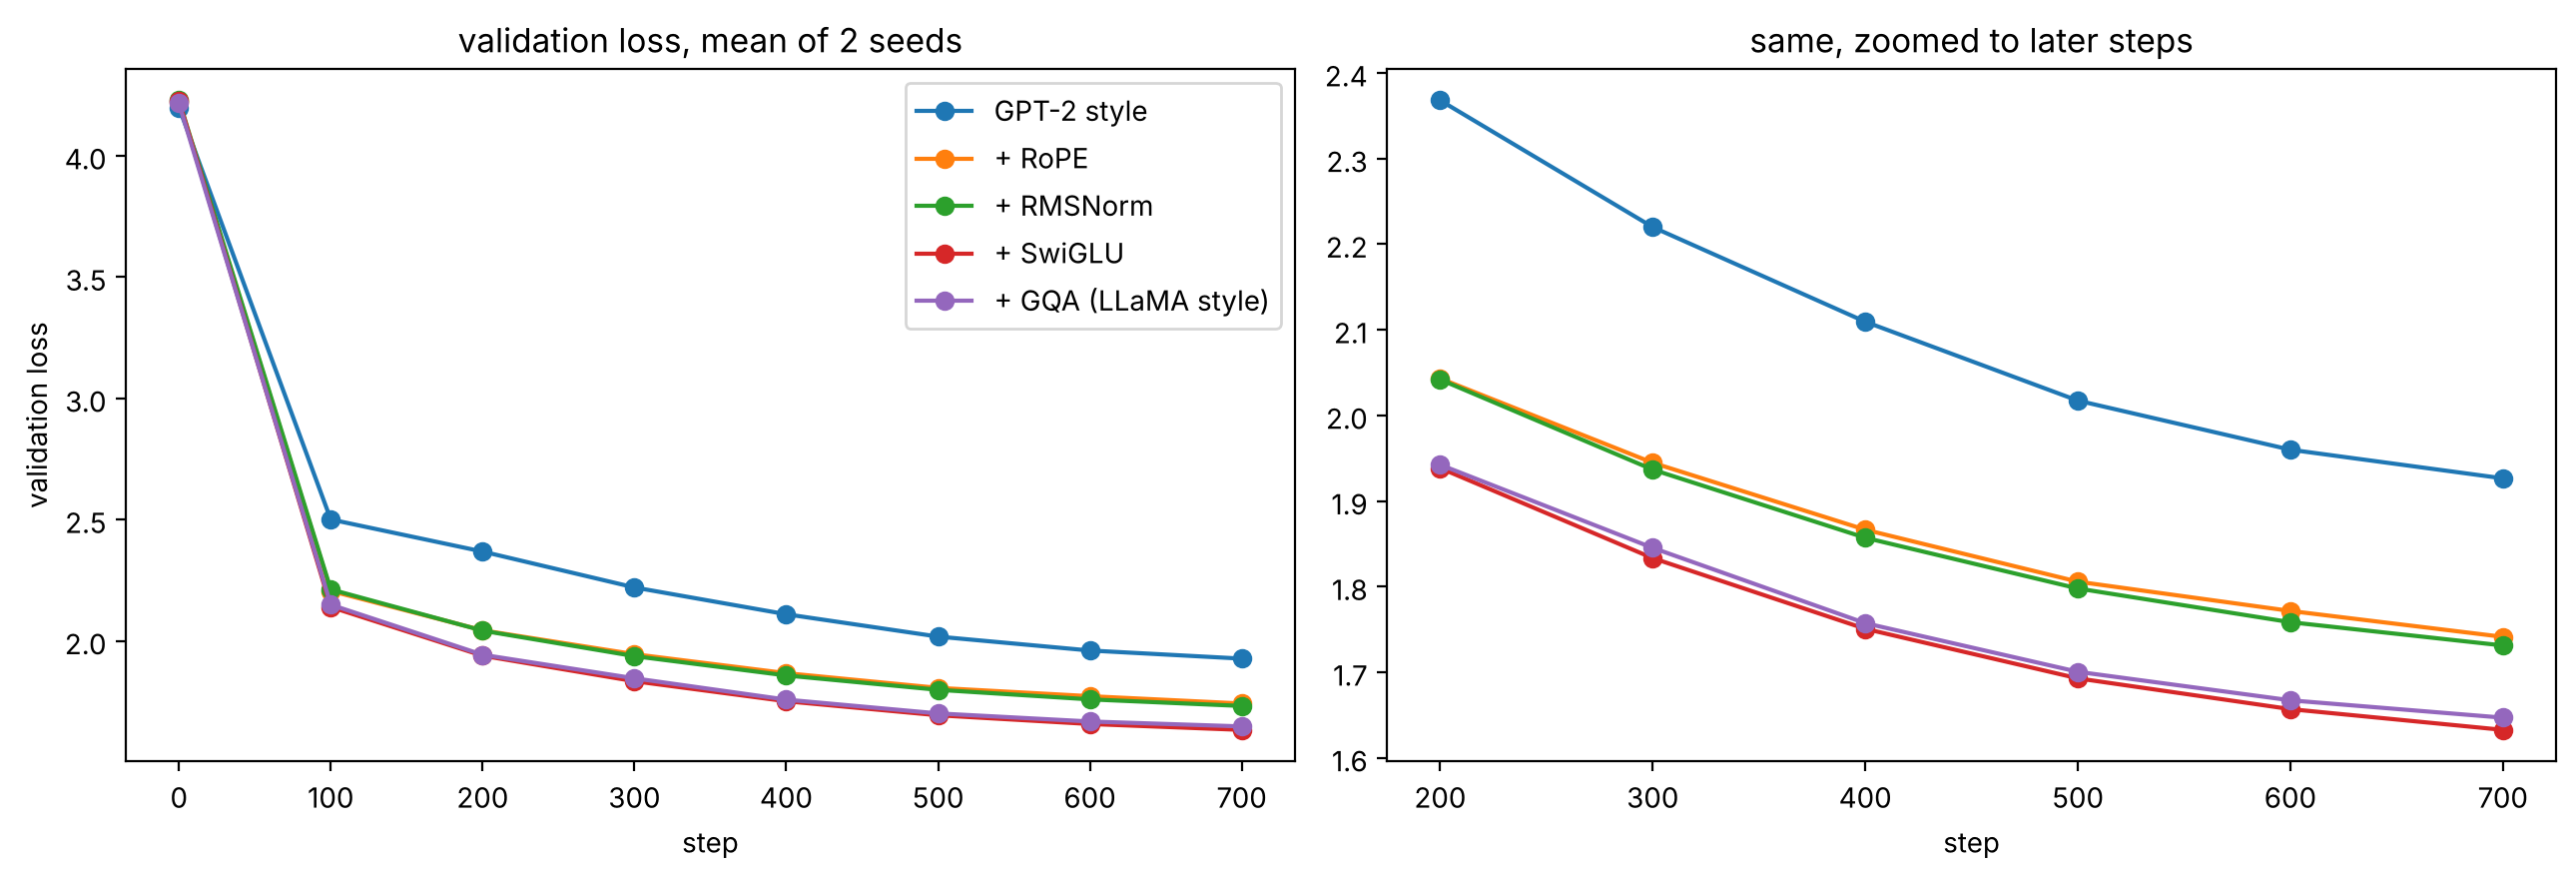

all variants learned (validation loss fell by more than 1.0 nat)


In [9]:
print(f"{'variant':22s} {'params':>9s} {'val loss (mean)':>16s} {'min':>8s} {'max':>8s} {'sec/run':>8s}")
for name, runs in results.items():
    finals = [r[0][-1][1] for r in runs]
    print(f"{name:22s} {runs[0][2]:9,d} {np.mean(finals):16.4f} {min(finals):8.4f} {max(finals):8.4f} {np.mean([r[1] for r in runs]):8.0f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, runs in results.items():
    its = [c[0] for c in runs[0][0]]
    mean_curve = np.mean([[c[1] for c in r[0]] for r in runs], axis=0)
    ax[0].plot(its, mean_curve, "o-", label=name)
    ax[1].plot(its[2:], mean_curve[2:], "o-", label=name)
ax[0].set_xlabel("step"); ax[0].set_ylabel("validation loss"); ax[0].legend(); ax[0].set_title("validation loss, mean of 2 seeds")
ax[1].set_xlabel("step"); ax[1].set_title("same, zoomed to later steps")
plt.tight_layout(); plt.show()

# sanity: every variant learned something real, and the two seeds agree on the ranking scale
for name, runs in results.items():
    for curve, _, _ in runs:
        assert curve[-1][1] < curve[0][1] - 1.0 and math.isfinite(curve[-1][1]), name
print("all variants learned (validation loss fell by more than 1.0 nat)")

## Sample from the LLaMA style model

Text generated with the KV cache from the last trained full model.

In [10]:
full_model = last_models["+ GQA (LLaMA style)"].eval()
start = torch.tensor([[data.stoi["\n"]]], device=device)
torch.manual_seed(0)
out = full_model.generate(start, 500, temperature=0.8, top_k=40, use_cache=True)[0].tolist()
print(data.decode(out))


Thou most kind self it one means by the gelst,
And pout you for bear again of bloody some offence.

POLIXENES:
Why, many soul wither none have too well.

RIVERROLIO:
O, they know I not sweet the read I fear.

CORIOLANUS:
I see, say, if to queen: or with the measure,
As think thy tongue good to my hand.

HORTENSIO:
Messenger I title for show, will be are he
Is shall souls good distrarge already.

COMINIUS:
O, now the world, But,
Therefore this loss and proportion tooother to love;
For thou hath h


## What to take from this

The test section confirms that every component is implemented correctly: RoPE is a true relative position encoding, GQA matches a per head reference, and the KV cache reproduces full forward passes exactly. The ablation table shows how each change affects learning speed on this small problem, with the seed spread shown so the size of real effects can be judged against noise. The cache benchmark shows the speedup for generation, and the cache size table shows why grouped query attention is used in larger models.